In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

/tmp/ipykernel_15369/687462750.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
DATA_PATH = '../../data'
MERGEGEN_RESULTS = '../../mergeGen/RESULTS'
SBCR_RESULTS = '../../sbcr'
ANALYSIS_PATH = '../../analysis'
INTERMEDIARY_RESULTS = f"{ANALYSIS_PATH}/intermediary_data"

MERGEGEN_DATASET2 = f"{MERGEGEN_RESULTS}/mergeGen_dataset2_JavaScript_model_dataset2_JavaScript_similarities.csv"
SBCR_DATASET2 = f"{SBCR_RESULTS}/rq2_JavaScript/RESULTS/results_evaluate_dataset2_JavaScript_combination_rq2_JavaScript_seed-3022024.xlsx"

DATASET2_COMPLETE = f"{DATA_PATH}/dataset2_JavaScript_complete.json" 
DATASET2_TESTING = f"{DATA_PATH}/dataset2_JavaScript_testing.json"
DATASET2_METADATA = f"{DATA_PATH}/dataset2_JavaScript_metadata.json"
DATASET2_STATS = f"{DATA_PATH}/dataset2_JavaScript_complete_stats.csv"

MERGEGEN_BETTER = f"{INTERMEDIARY_RESULTS}/rq4_dataset2_JavaScript_qualitative_list_MergegenBetter.csv"
SBCR_BETTER = f"{INTERMEDIARY_RESULTS}/rq4_dataset2_JavaScript_qualitative_list_SBCRBetter.csv"

In [3]:
df_complete_ds2 = pd.read_json(DATASET2_COMPLETE)

In [4]:
df_test_ds2 = pd.read_json(DATASET2_TESTING)
df_test_ds2

,all_raw_base,all_raw_a,all_raw_b,all_raw_res,merge_id,chunk_number
0,"},{""../lang/isArray"":144,""./bindCallback"":98}]...","},{""../lang/isArray"":141,""./bindCallback"":95}]...","\n},{""../lang/isArray"":142,""./bindCallback"":96...","},{""../lang/isArray"":141,""./bindCallback"":95}]...",23593,76
1,"\t},\n\t\n\trefreshGrid : function(fromGridEle...","},\n\n refreshGrid: function(fromGridEl...","\n\t},\n\t\n\trefreshGrid : function(fromGridE...","},\n\n refreshGrid: function(fromGridEl...",77774,3
2,\t setShowChildren: function(visible){\n\t ...,\t verifyProps: function () {\n\t if...,\n\t setShowChildren: function(visible){\n\...,\t verifyProps: function () {\n\t if...,61241,13
3,"\t\t\tslotWidth = mathMin(axis.slotWidth, slot...","\t\t\tslotWidth = Math.min(axis.slotWidth, slo...","\n\t\t\tslotWidth = mathMin(axis.slotWidth, sl...","\t\t\tslotWidth = Math.min(axis.slotWidth, slo...",118829,16
4,"},{""./_descriptors"":30,""./_export"":34,""./_obje...","\n},{""./_descriptors"":31,""./_export"":35,""./_ob...","\n\n},{""./_descriptors"":31,""./_export"":35,""./_...","\n},{""./_descriptors"":31,""./_export"":35,""./_ob...",155033,245
...,...,...,...,...,...,...
5144,"$routeProvider.when('/images/:id/', {t...","$routeProvider.when('/images/:id*/', {...","\n $routeProvider.when('/images/:id/', ...","$routeProvider.when('/images/:id*/', {...",203419,1
5145,"<Image className=""theme-cover"" src...","<Image className=""theme-cover"" src...",\n,,34496,2
5146,if (process.env.NODE_ENV === 'production') {\n...,"function bailoutHooks(current, workInProgress,...",\nif (process.env.NODE_ENV === 'production') {...,"function bailoutHooks(current, workInProgress,...",43162,28
5147,WebhookEndpoint.getFresh({id: $rou...,\n $q.all([\n FormEndp...,\n // @uirouter-refactor this is ve...,\n $q.all([\n FormEndp...,122669,3


In [5]:
df_mergegen_ds2 = pd.read_csv(MERGEGEN_DATASET2)
data = []
for index, row in df_mergegen_ds2.iterrows():
    chunk = df_complete_ds2.iloc[row['chunk_index']]
    chunk_id = f"{chunk['merge_id']}-{chunk['chunk_number']}"
    data.append(chunk_id)
df_mergegen_ds2['chunk_id'] = data
df_mergegen_ds2 = df_mergegen_ds2.rename(columns={"complete_similarity": "sim_mergegen", "time": "time_mergegen", "similarity":"sim_mergegen_trunc", "parents_similarity":"mergegen_parents_sim"})
df_mergegen_ds2

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim,result,chunk_id
0,27472,0.750000,0.666667,0.040468,1.000000,0.833333,0.916667,FAIL,196911-655
1,44031,0.997118,0.996904,0.342645,0.632911,0.948012,0.790462,FAIL,132648-2
2,35805,0.413514,0.416901,1.357956,0.416901,0.811475,0.614188,FAIL,55561-5
3,5646,0.763158,0.747664,0.307735,0.679012,0.654088,0.666550,FAIL,186409-1
4,17768,0.067797,0.037855,1.354022,0.096552,0.079395,0.087973,FAIL,132448-1
...,...,...,...,...,...,...,...,...,...
5144,1777,1.000000,1.000000,0.133554,1.000000,0.818182,0.909091,SUCCEED,179265-35
5145,41526,1.000000,1.000000,0.314328,1.000000,1.000000,1.000000,SUCCEED,89711-7
5146,24635,1.000000,1.000000,0.168448,1.000000,0.706897,0.853448,SUCCEED,187801-4
5147,37477,0.842553,1.000000,1.035379,0.665687,0.399317,0.532502,SUCCEED,161382-1


In [6]:
df_mergegen_ds2.describe()

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim
count,5149.000000,5149.000000,5149.000000,5149.000000,5149.000000,5149.000000,5149.000000
mean,25465.772577,0.867368,0.859217,0.520664,0.709729,0.670368,0.690048
std,14789.406424,0.238136,0.263065,0.459070,0.322154,0.335929,0.240918
min,4.000000,0.000000,0.000000,0.027127,0.000000,0.000000,0.000000
25%,12683.000000,0.787234,0.840532,0.174119,0.534428,0.447387,0.544152
50%,25379.000000,1.000000,1.000000,0.316305,0.834951,0.790698,0.709928
75%,38330.000000,1.000000,1.000000,0.728654,0.976109,0.962963,0.893258
max,51469.000000,1.000000,1.000000,1.530960,1.000000,1.000000,1.000000


In [7]:
df_sbcr_ds2 = pd.read_excel(SBCR_DATASET2)
df_sbcr_ds2 = df_sbcr_ds2.rename(columns={"solution_sim_lcs": "sim_sbcr", "time_seconds": "time_sbcr", "fitness": "fitness_sbcr"})
df_sbcr_ds2.sort_values('chunk_id')

,chunk_id,fitness_sbcr,sim_sbcr,status,time_sbcr
926,100159-1,0.902690,0.994778,ok,12.939296
1032,10096-1,0.926265,0.980803,ok,3.973917
1062,101479-1,0.643705,0.719136,ok,12.103017
995,101524-1,0.601941,0.292103,ok,65.247741
960,101528-1,0.916118,0.946363,ok,22.631450
...,...,...,...,...,...
1156,99230-1,0.993080,1.000000,ok,24.513543
416,9947-2,0.874936,0.735484,ok,7.194102
109,99477-1,0.901962,0.642943,ok,3.712581
477,99588-1,0.913930,1.000000,ok,19.721328


In [8]:
df_results_ds2 = df_sbcr_ds2[['chunk_id', 'fitness_sbcr', 'sim_sbcr', 'time_sbcr']].merge(df_mergegen_ds2[['chunk_index', 'chunk_id', 'sim_mergegen', 'time_mergegen', 'mergegen_parents_sim']], on='chunk_id', suffixes=('_sbcr', '_mergegen'))
df_results_ds2

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim
0,4314-130,0.839161,1.000000,22.699592,8140,1.000000,0.168681,0.827331
1,161562-10,0.978183,0.959641,22.313421,26525,1.000000,0.262166,0.972083
2,156864-1,0.876318,0.747664,21.497840,44495,1.000000,0.186749,0.861000
3,37347-2,0.811602,1.000000,23.151990,42547,1.000000,0.201570,0.814852
4,194169-2,0.801728,0.648373,4.807784,30716,0.922025,1.348341,0.777483
...,...,...,...,...,...,...,...,...
1302,146509-2,0.910324,0.932765,21.175079,32859,0.978890,1.354858,0.963552
1303,68491-34,0.599088,0.991239,0.828199,10797,1.000000,0.616231,0.594733
1304,193794-4,0.855649,0.975684,1.564690,6000,1.000000,0.483217,0.826774
1305,90072-300,0.829473,0.848485,2.340068,42473,0.717949,0.370072,0.667072


In [9]:
print(df_results_ds2['sim_sbcr'].isnull().sum()) 
df_results_clean = df_results_ds2.dropna(subset=['sim_sbcr', 'sim_mergegen'])

12


In [10]:
print(df_results_clean[['sim_sbcr', 'sim_mergegen', 'time_sbcr', 'time_mergegen']].describe())

          sim_sbcr  sim_mergegen    time_sbcr  time_mergegen
count  1295.000000   1295.000000  1295.000000    1295.000000
mean      0.814622      0.877370    14.814825       0.531898
std       0.210181      0.223208    17.080710       0.449940
min       0.003898      0.000000     0.257957       0.040358
25%       0.706919      0.835708     3.069293       0.193806
50%       0.887179      1.000000    13.380127       0.334574
75%       0.994127      1.000000    22.536076       0.713305
max       1.000000      1.000000   231.273514       1.367894


In [11]:
df_results_clean['diff'] = df_results_clean['sim_sbcr'] - df_results_clean['sim_mergegen']
df_results_clean

/tmp/ipykernel_15369/520408852.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_results_clean['diff'] = df_results_clean['sim_sbcr'] - df_results_clean['sim_mergegen']


,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff
0,4314-130,0.839161,1.000000,22.699592,8140,1.000000,0.168681,0.827331,0.000000
1,161562-10,0.978183,0.959641,22.313421,26525,1.000000,0.262166,0.972083,-0.040359
2,156864-1,0.876318,0.747664,21.497840,44495,1.000000,0.186749,0.861000,-0.252336
3,37347-2,0.811602,1.000000,23.151990,42547,1.000000,0.201570,0.814852,0.000000
4,194169-2,0.801728,0.648373,4.807784,30716,0.922025,1.348341,0.777483,-0.273652
...,...,...,...,...,...,...,...,...,...
1302,146509-2,0.910324,0.932765,21.175079,32859,0.978890,1.354858,0.963552,-0.046125
1303,68491-34,0.599088,0.991239,0.828199,10797,1.000000,0.616231,0.594733,-0.008761
1304,193794-4,0.855649,0.975684,1.564690,6000,1.000000,0.483217,0.826774,-0.024316
1305,90072-300,0.829473,0.848485,2.340068,42473,0.717949,0.370072,0.667072,0.130536


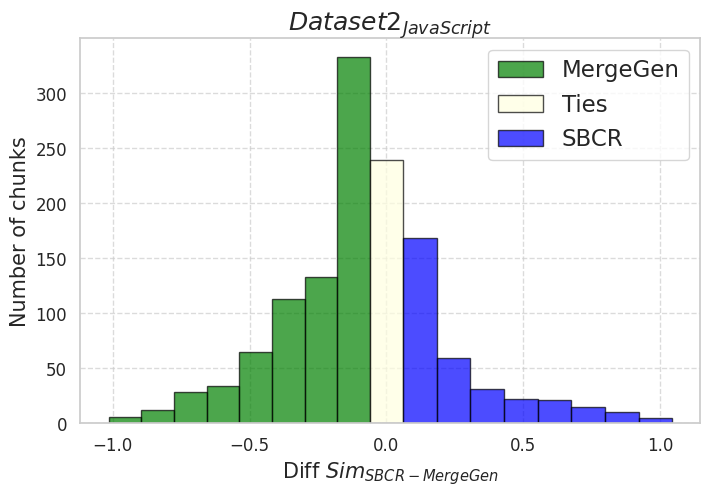

In [31]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

# Get the 'diff' data from the DataFrame
data = df_results_clean['diff']

# Split the data into three groups:
# - left_data: values less than 0
# - center_data: values equal to 0
# - right_data: values greater than 0
left_data   = data[data < 0]
center_data = data[data == 0]
right_data  = data[data > 0]

# Define the number of bins for the left and right groups
n_bins_left  = 8
n_bins_right = 8

# Create bins for the left side covering the entire range of negative values
left_bins = np.linspace(left_data.min(), 0, n_bins_left + 1)
# Create bins for the right side covering the entire range of positive values
right_bins = np.linspace(0, right_data.max(), n_bins_right + 1)

# Compute histogram counts for left and right data
left_counts, _  = np.histogram(left_data, bins=left_bins)
right_counts, _ = np.histogram(right_data, bins=right_bins)

# Calculate the original centers and widths of the bins
left_centers_orig  = (left_bins[:-1] + left_bins[1:]) / 2
right_centers_orig = (right_bins[:-1] + right_bins[1:]) / 2
left_widths  = np.diff(left_bins)
right_widths = np.diff(right_bins)

# Set the central bin's width as the average of the last left bin's width and the first right bin's width
central_width = (left_widths[-1] + right_widths[0]) / 2

# For a visual gap, shift the left centers to the left by central_width/2 and the right centers to the right by central_width/2.
# This moves the left bars so that their rightmost edge becomes -central_width/2,
# and the right bars so that their leftmost edge becomes +central_width/2.
left_centers  = left_centers_orig - central_width/2
right_centers = right_centers_orig + central_width/2

# Count the number of values that are exactly 0 (for the center bin)
center_count = len(center_data)

# Plot the histogram
plt.figure(figsize=(8, 5))

# Plot the left bars (values < 0)
plt.bar(left_centers, left_counts, width=left_widths,
        color='green', edgecolor='black', alpha=0.7, label="MergeGen")

# Plot the center bar (values == 0) at x = 0 with the computed central_width
plt.bar(0, center_count, width=central_width,
        color='lightyellow', edgecolor='black', alpha=0.7, label="Ties")

# Plot the right bars (values > 0)
plt.bar(right_centers, right_counts, width=right_widths,
        color='blue', edgecolor='black', alpha=0.7, label="SBCR")

# Final plot configurations
plt.title('$Dataset2_{JavaScript}$')
plt.xlabel('Diff $Sim_{SBCR-MergeGen}$', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.show()

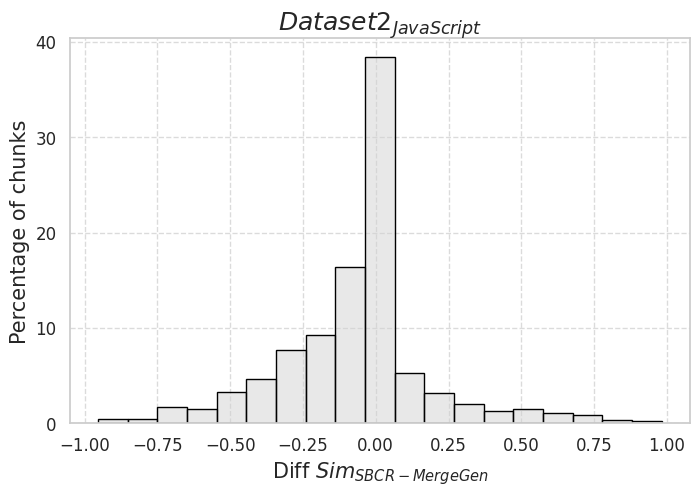

In [12]:
# close to 1 = sbcr is better
# close to -1 = mergegen is better
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)
bins = 19
plt.figure(figsize=(8, 5))
ax = sns.histplot(df_results_clean['diff'], bins=bins, stat='percent',color='lightgray', label="$Dataset1$", edgecolor='black', alpha=0.5)
# ax = sns.histplot(dataset2_Java['diff'], bins=bins, stat='percent', color='blue', label="$Dataset2_{Java}$", edgecolor='black', alpha=0.5)

plt.title('$Dataset2_{JavaScript}$')
plt.xlabel('Diff $Sim_{SBCR-MergeGen}$', fontsize=15)
plt.ylabel('Percentage of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim(-40,40)
# plt.legend()
plt.show()

In [13]:
df_stats = pd.read_csv(DATASET2_STATS)
df = df_results_clean.merge(df_stats, on='chunk_id')
df['diff_chunk_solution'] = df['chunk_size_char'] - df['solution_size_char']
df['chunk_diff_lines'] = df['v1_size'] - df['v2_size']
df['v1_size_rel'] = df['v1_size']/(df['v1_size'] + df['v2_size'])
df['v2_size_rel'] = df['v2_size']/(df['v1_size'] + df['v2_size'])
df['chunk_diff_lines_rel'] = df['v1_size_rel'] - df['v2_size_rel']
df['chunk_diff_char'] = df['v1_size_char'] - df['v2_size_char']
df['v1_size_char_rel'] = df['v1_size_char']/(df['v1_size_char'] + df['v2_size_char'])
df['v2_size_char_rel'] = df['v2_size_char']/(df['v1_size_char'] + df['v2_size_char'])
df['chunk_diff_char_rel'] = df['v1_size_char_rel'] - df['v2_size_char_rel']
df

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,resolution_parents_sim,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel
0,4314-130,0.839161,1.000000,22.699592,8140,1.000000,0.168681,0.827331,0.000000,4,...,0.839161,22,0,0.500000,0.500000,0.000000,10,0.571429,0.428571,0.142857
1,161562-10,0.978183,0.959641,22.313421,26525,1.000000,0.262166,0.972083,-0.040359,5,...,0.977556,118,-1,0.400000,0.600000,-0.200000,6,0.513274,0.486726,0.026549
2,156864-1,0.876318,0.747664,21.497840,44495,1.000000,0.186749,0.861000,-0.252336,5,...,0.870071,114,-1,0.400000,0.600000,-0.200000,-1,0.497696,0.502304,-0.004608
3,37347-2,0.811602,1.000000,23.151990,42547,1.000000,0.201570,0.814852,0.000000,4,...,0.811322,60,-2,0.250000,0.750000,-0.500000,-69,0.315508,0.684492,-0.368984
4,194169-2,0.801728,0.648373,4.807784,30716,0.922025,1.348341,0.777483,-0.273652,15,...,0.807138,449,-5,0.333333,0.666667,-0.333333,-515,0.329357,0.670643,-0.341286
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1290,146509-2,0.910324,0.932765,21.175079,32859,0.978890,1.354858,0.963552,-0.046125,44,...,0.927388,906,6,0.568182,0.431818,0.136364,279,0.572317,0.427683,0.144635
1291,68491-34,0.599088,0.991239,0.828199,10797,1.000000,0.616231,0.594733,-0.008761,15,...,0.598489,54,9,0.800000,0.200000,0.600000,359,0.894505,0.105495,0.789011
1292,193794-4,0.855649,0.975684,1.564690,6000,1.000000,0.483217,0.826774,-0.024316,13,...,0.854648,450,-1,0.461538,0.538462,-0.076923,-127,0.418065,0.581935,-0.163871
1293,90072-300,0.829473,0.848485,2.340068,42473,0.717949,0.370072,0.667072,0.130536,8,...,0.817609,43,0,0.500000,0.500000,0.000000,18,0.562500,0.437500,0.125000


In [14]:
# cases where mergeGen is better
print(len(df[df['diff'] < 0]))
df.sort_values('diff').to_csv(MERGEGEN_BETTER)
df.sort_values('diff').head(20)


725


,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,resolution_parents_sim,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel
12,30136-79,0.495795,0.023299,23.260180,10497,0.977273,0.114571,0.499795,-0.953974,49,...,0.494639,4002,45,0.959184,0.040816,0.918367,3955,0.988634,0.011366,0.977267
1137,95118-1,0.521718,0.079082,2.460983,22113,1.000000,0.079695,0.374074,-0.920918,22,...,0.387600,740,-20,0.045455,0.954545,-0.909091,-738,0.022021,0.977979,-0.955959
737,79251-3,0.539463,0.066956,6.767694,45736,0.961538,0.113538,0.345882,-0.894582,32,...,0.372598,1559,-26,0.093750,0.906250,-0.812500,-1449,0.051948,0.948052,-0.896104
890,35634-1,0.501470,0.108209,1.231924,16873,1.000000,0.087976,0.057018,-0.891791,12,...,0.088551,480,10,0.916667,0.083333,0.833333,509,0.998043,0.001957,0.996086
139,115747-1,0.548685,0.112175,2.574897,3972,1.000000,0.060952,0.440564,-0.887825,21,...,0.442763,691,17,0.904762,0.095238,0.809524,651,0.944065,0.055935,0.888131
283,4855-5,0.541741,0.132659,48.659690,9185,1.000000,0.804993,0.482886,-0.867341,237,...,0.505605,8669,-213,0.050633,0.949367,-0.898734,-8148,0.060043,0.939957,-0.879914
1201,29771-1,0.539557,0.166667,1.612610,43485,1.000000,0.107752,0.437983,-0.833333,25,...,0.419868,531,-23,0.040000,0.960000,-0.920000,-532,0.049153,0.950847,-0.901695
367,4697-15,0.530176,0.197731,28.585669,36471,0.997449,1.346676,0.581553,-0.799718,165,...,0.582883,5678,-137,0.084848,0.915152,-0.830303,-5152,0.084784,0.915216,-0.830432
1123,221482-5,0.502333,0.203966,11.549762,45753,0.983607,0.060541,0.099010,-0.779641,9,...,0.130248,283,7,0.888889,0.111111,0.777778,318,0.996875,0.003125,0.993750
995,161862-1,0.612752,0.228261,2.587882,44064,1.000000,0.437120,0.582778,-0.771739,11,...,0.586180,328,-9,0.090909,0.909091,-0.818182,-287,0.113208,0.886792,-0.773585


In [15]:
# cases where sbcr is better
print(len(df[df['diff'] > 0]))
df.sort_values('diff', ascending=False).to_csv(SBCR_BETTER)
df.sort_values('diff', ascending=False).head(20)

331


,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,resolution_parents_sim,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel
376,60354-1,0.523673,0.997680,1.432050,24264,0.015306,0.598778,0.257692,0.982374,17,...,0.523564,9,13,0.882353,0.117647,0.764706,421,0.975169,0.024831,0.950339
915,123269-5,0.501313,0.980144,2.514821,2973,0.000000,1.229395,0.500000,0.980144,22,...,0.491556,22,20,0.954545,0.045455,0.909091,570,0.998252,0.001748,0.996503
399,71248-1,0.536735,0.995885,23.839131,39726,0.033333,0.067515,0.416529,0.962551,4,...,0.529455,6,0,0.500000,0.500000,0.000000,118,0.960938,0.039062,0.921875
1212,119250-1,0.490032,0.894100,38.578825,34961,0.000000,1.367894,0.500000,0.894100,235,...,0.458992,1335,233,0.995745,0.004255,0.991489,8772,0.999886,0.000114,0.999772
461,50730-3,0.502104,0.872204,0.603494,41625,0.000000,0.420790,0.500000,0.872204,9,...,0.439942,81,7,0.888889,0.111111,0.777778,353,0.997183,0.002817,0.994366
114,104212-18,0.832536,0.847699,26.260334,39304,0.016333,1.350313,0.022122,0.831366,5,...,0.819489,514,-1,0.400000,0.600000,-0.200000,15,0.504092,0.495908,0.008183
844,104212-10,0.814347,0.844385,27.551561,39296,0.021825,1.367247,0.029237,0.822560,5,...,0.812727,362,-1,0.400000,0.600000,-0.200000,18,0.506726,0.493274,0.013453
419,82997-1,0.803983,0.940749,101.868306,28774,0.145329,1.348829,0.147182,0.795420,520,...,0.840967,7006,16,0.515385,0.484615,0.030769,944,0.531576,0.468424,0.063152
565,104226-11,0.896723,0.811271,24.423402,26841,0.018219,1.354769,0.024138,0.793052,5,...,0.829084,382,-1,0.400000,0.600000,-0.200000,-152,0.440532,0.559468,-0.118936
125,104226-5,0.886195,0.818383,21.315772,26835,0.040665,1.350608,0.055969,0.777718,7,...,0.825017,662,-1,0.428571,0.571429,-0.142857,-305,0.432192,0.567808,-0.135616


In [16]:
df_mergegen = df[df['diff'] < 0]
df_sbcr = df[df['diff'] > 0]

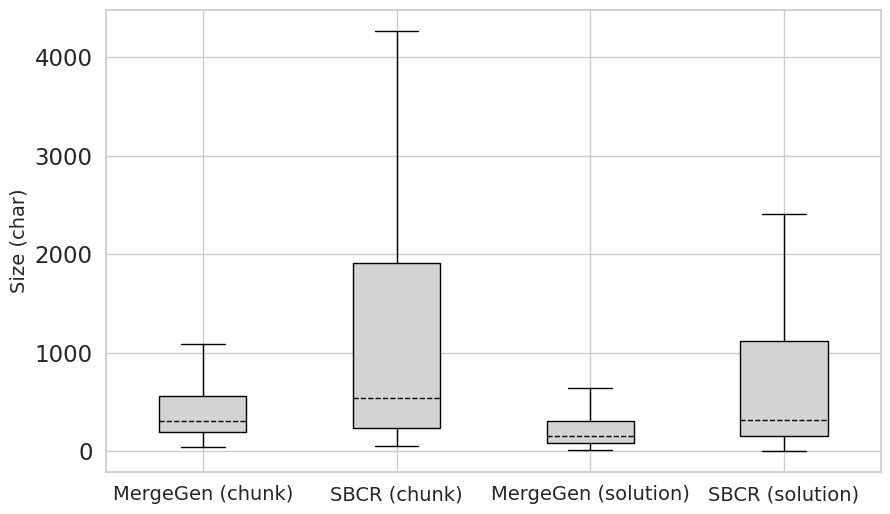

In [17]:
# Create a boxplot
plt.figure(figsize=(10, 6))  # Set the figure size
plt.boxplot([df_mergegen['chunk_size_char'], df_sbcr['chunk_size_char'], df_mergegen['solution_size_char'], df_sbcr['solution_size_char']], 
            patch_artist=True,  # To fill the box with color
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  # Color of the median line
            boxprops=dict(facecolor='lightgray', color='black'),  # Color of the box
            whiskerprops=dict(color='black'),  # Color of the whiskers
            capprops=dict(color='black'),  # Color of the caps
            showfliers=False)  # Properties of the outliers

# Customize labels and title
# plt.xlabel('Your X Label')
plt.ylabel('Size (char)', fontsize=14)
plt.xticks([1, 2, 3, 4], ['MergeGen (chunk)', 'SBCR (chunk)', 'MergeGen (solution)', 'SBCR (solution)'], fontsize=14)
# plt.title('Similarity between random candidates and parents \n using each aggregation function', fontsize=16)

# Save or show the plot
# plt.savefig('RQ3_boxplots.png', dpi=300)  # Save the plot as a PNG file with higher resolution
plt.show()  # Show the plot

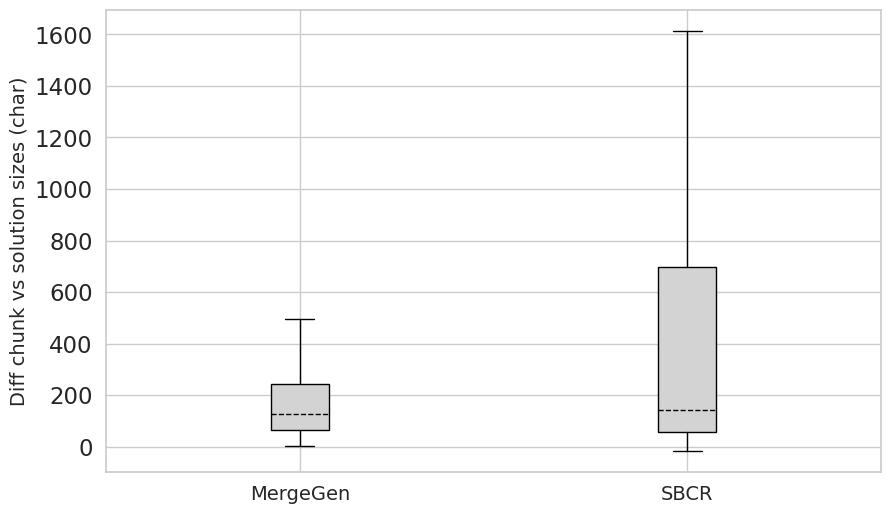

In [18]:
plt.figure(figsize=(10, 6))  # Set the figure size
plt.boxplot([df_mergegen['diff_chunk_solution'], df_sbcr['diff_chunk_solution']], 
            patch_artist=True,  # To fill the box with color
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  # Color of the median line
            boxprops=dict(facecolor='lightgray', color='black'),  # Color of the box
            whiskerprops=dict(color='black'),  # Color of the whiskers
            capprops=dict(color='black'),  # Color of the caps
            showfliers=False)  # Properties of the outliers

plt.ylabel('Diff chunk vs solution sizes (char)', fontsize=14)
plt.xticks([1, 2], ['MergeGen', 'SBCR'], fontsize=14)

plt.show()  # Show the plot

In [19]:
print(df_mergegen[['fitness_sbcr','diff_chunk_solution']].describe())
print(df_sbcr[['fitness_sbcr','diff_chunk_solution']].describe())
            

       fitness_sbcr  diff_chunk_solution
count    725.000000           725.000000
mean       0.768591           263.686897
std        0.138791           630.073049
min        0.493506             1.000000
25%        0.677840            66.000000
50%        0.794515           126.000000
75%        0.874179           242.000000
max        0.997319          8669.000000
       fitness_sbcr  diff_chunk_solution
count    331.000000           331.000000
mean       0.769429           827.688822
std        0.137891          2078.091602
min        0.379269           -16.000000
25%        0.686227            55.500000
50%        0.791780           141.000000
75%        0.877298           698.000000
max        0.998307         19881.000000


In [20]:
df['fitness_to_solution_diff'] = df['mergegen_parents_sim'] - df['fitness_sbcr']

In [21]:
df[(df['diff'] < 0) & (df['mergegen_parents_sim'] > df['fitness_sbcr'])].sort_values('fitness_to_solution_diff', ascending=False)

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel,fitness_to_solution_diff
1205,192404-1,0.791428,0.901493,18.024160,2519,1.000000,0.141772,0.920935,-0.098507,7,...,112,-5,0.142857,0.857143,-0.714286,-108,0.295455,0.704545,-0.409091,0.129507
918,92286-3,0.740868,0.537530,2.598397,6604,1.000000,0.229085,0.870139,-0.462470,11,...,165,7,0.818182,0.181818,0.636364,242,0.758547,0.241453,0.517094,0.129271
465,175299-2,0.757961,0.672355,1.375161,2577,0.683453,0.422170,0.812360,-0.011098,12,...,211,6,0.750000,0.250000,0.500000,221,0.740741,0.259259,0.481481,0.054398
544,144724-1,0.785620,0.794781,22.519257,14318,0.995526,1.358146,0.839233,-0.200745,83,...,1521,19,0.614458,0.385542,0.228916,630,0.641892,0.358108,0.283784,0.053612
1290,146509-2,0.910324,0.932765,21.175079,32859,0.978890,1.354858,0.963552,-0.046125,44,...,906,6,0.568182,0.431818,0.136364,279,0.572317,0.427683,0.144635,0.053228
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
937,52173-1,0.722483,0.991453,2.884556,48772,1.000000,0.720428,0.722904,-0.008547,24,...,105,10,0.708333,0.291667,0.416667,246,0.736538,0.263462,0.473077,0.000421
344,223035-1,0.566181,0.075431,3.585284,42081,0.727273,0.215699,0.566587,-0.651842,38,...,928,-34,0.052632,0.947368,-0.894737,-836,0.066390,0.933610,-0.867220,0.000406
11,23322-2,0.930598,0.890511,22.134578,44772,1.000000,0.099827,0.930815,-0.109489,5,...,75,-1,0.400000,0.600000,-0.200000,-19,0.430657,0.569343,-0.138686,0.000217
48,7979-1,0.993166,0.994475,21.270980,18032,1.000000,0.328085,0.993333,-0.005525,5,...,183,-1,0.400000,0.600000,-0.200000,-1,0.498630,0.501370,-0.002740,0.000168


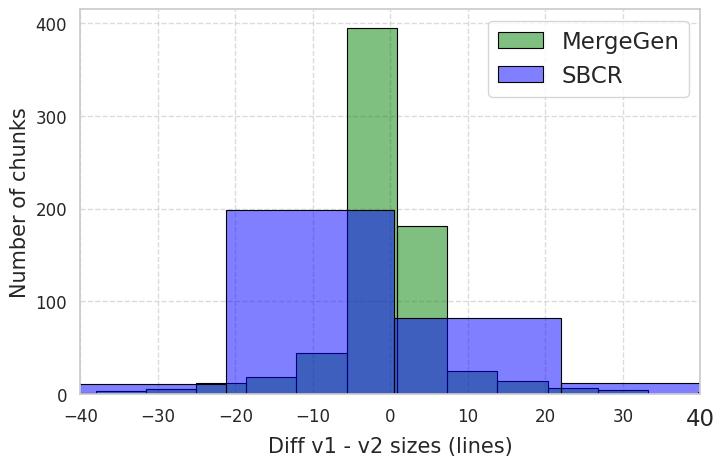

In [22]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_lines'], bins=50, color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_lines'],bins=50, color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (lines)', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(-40,40)
plt.legend()
plt.show()

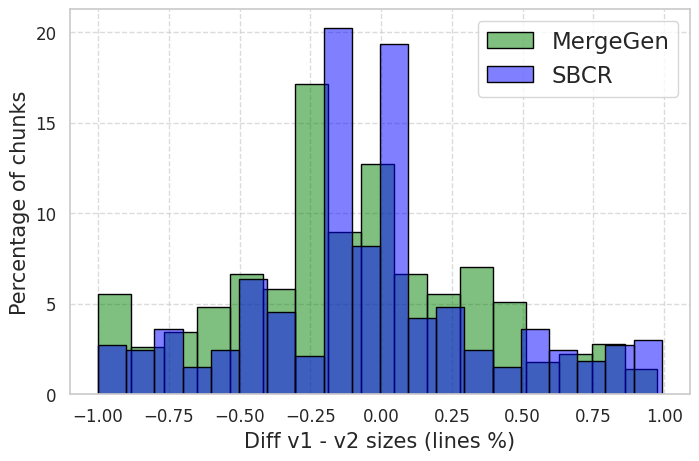

In [23]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_lines_rel'], stat='percent',color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_lines_rel'], stat='percent', color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (lines %)', fontsize=15)
plt.ylabel('Percentage of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim(-40,40)
plt.legend()
plt.show()

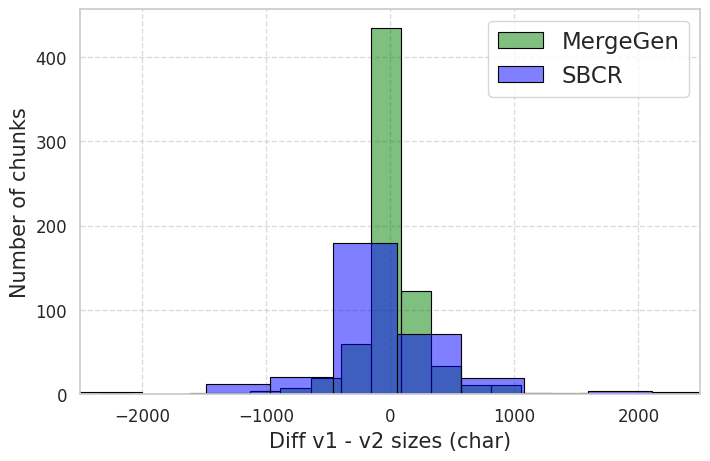

In [24]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_char'], bins=50, color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_char'],bins=50, color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (char)', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(-2500,2500)
plt.legend()
plt.show()

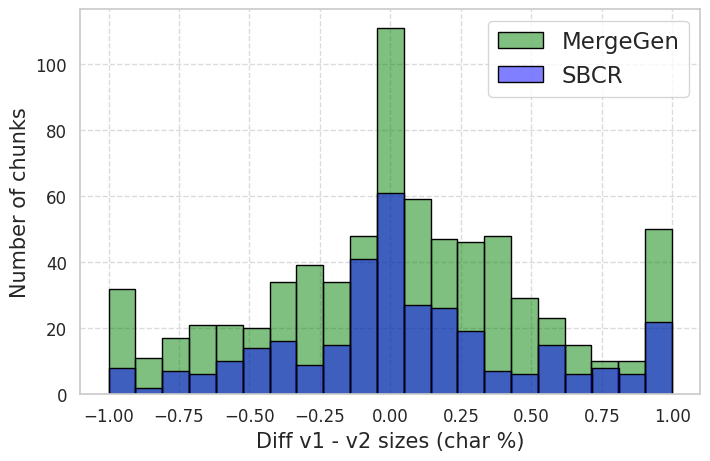

In [25]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_char_rel'], bins=21, color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_char_rel'], bins=21, color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (char %)', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim(-40,40)
plt.legend()
plt.show()

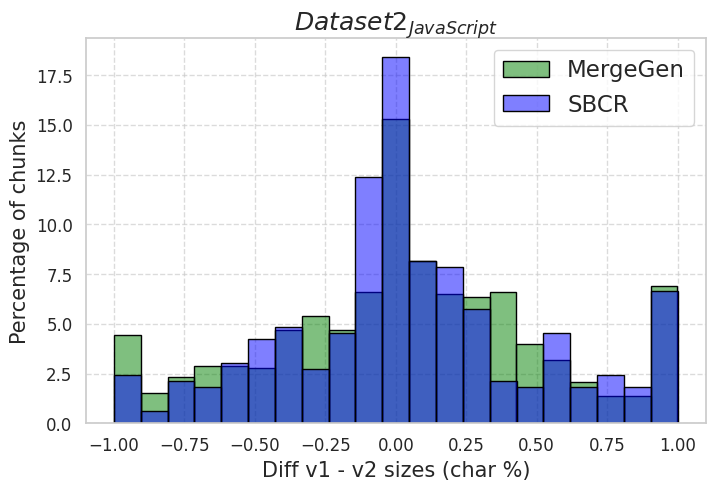

In [26]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_char_rel'], bins=21, stat='percent',color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_char_rel'], bins=21, stat='percent', color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.title('$Dataset2_{JavaScript}$')
plt.xlabel('Diff v1 - v2 sizes (char %)', fontsize=15)
plt.ylabel('Percentage of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim(-40,40)
plt.legend()
plt.show()

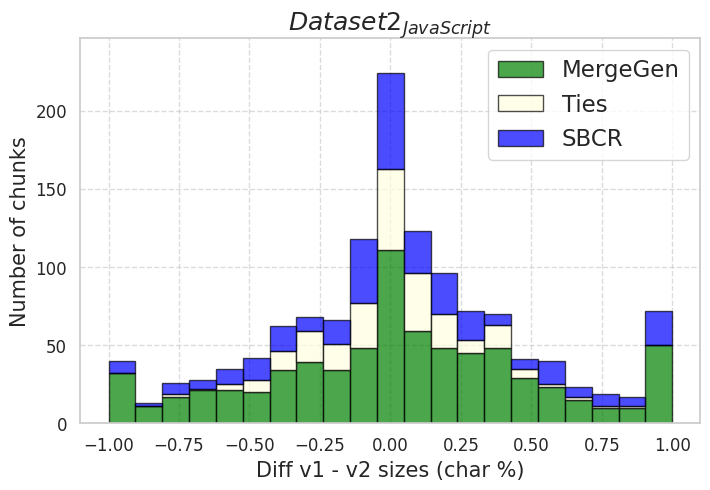

In [30]:
df_tie = df[df['diff'] == 0]

# Configuração do estilo
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

# Definir bins comuns para ambos os conjuntos de dados
bins = np.linspace(min(df_mergegen['chunk_diff_char_rel'].min(), df_sbcr['chunk_diff_char_rel'].min(), df_tie['chunk_diff_char_rel'].min()),
                   max(df_mergegen['chunk_diff_char_rel'].max(), df_sbcr['chunk_diff_char_rel'].max(), df_tie['chunk_diff_char_rel'].max()), 22)

# Contar a frequência de cada abordagem nos bins
hist_mergegen, _ = np.histogram(df_mergegen['chunk_diff_char_rel'], bins=bins)
hist_sbcr, _ = np.histogram(df_sbcr['chunk_diff_char_rel'], bins=bins)
hist_tie, _ = np.histogram(df_tie['chunk_diff_char_rel'], bins=bins)


# # Normalizar para obter a porcentagem individual dentro de cada categoria
# hist_mergegen = (hist_mergegen / hist_mergegen.sum()) * 100
# hist_sbcr = (hist_sbcr / hist_sbcr.sum()) * 100

# Posições centrais dos bins
bin_centers = (bins[:-1] + bins[1:]) / 2

# Criar stacked bar plot
plt.figure(figsize=(8, 5))


plt.bar(bin_centers, hist_mergegen, width=np.diff(bins), color='green', edgecolor='black', label="MergeGen", alpha=0.7)
plt.bar(bin_centers, hist_tie, width=np.diff(bins), color='lightyellow', edgecolor='black', label="Ties", alpha=0.7, bottom=hist_mergegen)
plt.bar(bin_centers, hist_sbcr, width=np.diff(bins), color='blue', edgecolor='black', label="SBCR", alpha=0.7, bottom=hist_mergegen+hist_tie)


# Ajuste do eixo Y
max_y = (hist_mergegen + hist_sbcr + hist_tie).max()  # Valor máximo das barras empilhadas
plt.ylim(0, max_y * 1.1)  # Adiciona 10% de margem superior para melhor visualização

# Rótulos e título
plt.title('$Dataset2_{JavaScript}$')
plt.xlabel('Diff v1 - v2 sizes (char %)', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

# Ajuste dos ticks
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Adicionar grid
plt.grid(True, linestyle='--', alpha=0.7)

# Adicionar legenda
plt.legend()

# Exibir plot
plt.show()
